# HQViT — Clean Restart Notebook
**Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer**  
CIFAR-10 · CPU-first · maximum 15 epochs.

This is a clean, linear replacement for the fragmented notebook. It preserves the original split procedure from Cells 12–13. It does not overwrite historical results or claim that the rebuilt HQViT is identical to the lost historical model/checkpoint.

**Important:** The original split seed must be recovered from `results/experiment_config.json` or entered explicitly. The notebook stops rather than guessing. The test set is reserved for final evaluation. Training is opt-in.

## 1. Imports and environment

In [4]:
import os, sys, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, random_split
import pennylane as qml
from sklearn.metrics import accuracy_score, classification_report

warnings.filterwarnings("ignore")
DEVICE = torch.device("cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("PennyLane:", qml.__version__)
print("Device:", DEVICE)

Python: 3.14.2
PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
PennyLane: 0.45.1
Device: cpu


## 2. Configuration and seed recovery

In [14]:
CONFIG_PATH = Path("results/experiment_config.json")
ORIGINAL_SEED = 42  # If config is missing, enter the exact original SEED here.

if CONFIG_PATH.exists():
    with open(CONFIG_PATH) as f:
        saved_config = json.load(f)
    if "seed" in saved_config:
        ORIGINAL_SEED = int(saved_config["seed"])

if ORIGINAL_SEED is None:
    raise RuntimeError(
        "Original seed not found. Set ORIGINAL_SEED to the exact SEED "
        "from the original notebook. Do not guess."
    )

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
BATCH_SIZE, MAX_EPOCHS = 32, 15
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 1e-4
DATA_FRACTIONS = (0.10, 0.25, 0.50, 1.00)
DATA_DIR = Path("data")
RESULTS_DIR = Path("results_clean")
CHECKPOINT_DIR = Path("checkpoints_clean")
RESULTS_DIR.mkdir(exist_ok=True, parents=True)
CHECKPOINT_DIR.mkdir(exist_ok=True, parents=True)
print("Original seed:", SEED)

Original seed: 42


## 3. CIFAR-10 and original split reconstruction

In [15]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

full_train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=transform
)
assert len(full_train_dataset) == 50000 and len(test_dataset) == 10000

# Original Cell 12: PyTorch random_split with seeded Generator.
split_generator = torch.Generator().manual_seed(SEED)
train_pool, validation_dataset = random_split(
    full_train_dataset, [45000, 5000], generator=split_generator
)

# Original Cell 13: independently seeded NumPy permutation of train_pool.
pool_order = np.random.default_rng(SEED).permutation(len(train_pool))
train_subsets = {
    f: Subset(train_pool, pool_order[:int(len(train_pool)*f)].tolist())
    for f in DATA_FRACTIONS
}
train_indices = list(train_pool.indices)
validation_indices = list(validation_dataset.indices)
assert not (set(train_indices) & set(validation_indices))
assert len(set(train_indices + validation_indices)) == 50000

print("Train pool:", len(train_pool), "| Validation:", len(validation_dataset),
      "| Test:", len(test_dataset))
for f, ds in train_subsets.items(): print(f"{f:.0%}:", len(ds))

Train pool: 45000 | Validation: 5000 | Test: 10000
10%: 4500
25%: 11250
50%: 22500
100%: 45000


## 4. Loaders and sanity check

In [16]:
def make_loaders(fraction=1.0, batch_size=BATCH_SIZE):
    tr = DataLoader(train_subsets[fraction], batch_size=batch_size,
                    shuffle=True, num_workers=0)
    va = DataLoader(validation_dataset, batch_size=batch_size,
                    shuffle=False, num_workers=0)
    return tr, va

train_loader, validation_loader = make_loaders(0.10)
x, y = next(iter(train_loader))
print("Batch:", tuple(x.shape), tuple(y.shape),
      "| finite:", bool(torch.isfinite(x).all()))
assert x.shape[1:] == (3, 32, 32) and torch.isfinite(x).all()

Batch: (32, 3, 32, 32) (32,) | finite: True


## 5. Model definitions

The comparison consists of a Classical ViT, a classical 4-dimensional bottleneck control, and a rebuilt 4-qubit HQViT. All are freshly initialized. The HQViT is the documented rebuilt implementation, **not** a reproduction of the missing historical weights.

In [17]:
class ViTBackbone(nn.Module):
    def __init__(self, dim=128, heads=4, layers=4, patch=4, dropout=0.1):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, dim, kernel_size=patch, stride=patch)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 65, dim))
        self.dropout = nn.Dropout(dropout)
        enc = nn.TransformerEncoderLayer(
            d_model=dim, nhead=heads, dim_feedforward=4*dim,
            dropout=dropout, batch_first=True, activation="gelu"
        )
        self.transformer = nn.TransformerEncoder(enc, num_layers=layers)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = self.dropout(torch.cat([cls, x], dim=1) + self.pos_embed)
        return self.transformer(x)[:, 0]

class ClassicalViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTBackbone()
        self.head = nn.Linear(128, 10)
    def forward(self, x): return self.head(self.vit(x))

class ClassicalBottleneck(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTBackbone()
        self.projection_norm = nn.LayerNorm(128)
        self.projection = nn.Linear(128, 4)
        self.classical_transform = nn.Sequential(nn.Linear(4, 4), nn.Tanh())
        self.classifier = nn.Sequential(nn.Linear(4, 32), nn.GELU(), nn.Linear(32, 10))
    def forward(self, x):
        z = self.projection(self.projection_norm(self.vit(x)))
        return self.classifier(self.classical_transform(z))

N_QUBITS, Q_LAYERS = 4, 2
qdev = qml.device("default.qubit", wires=N_QUBITS, shots=None)

@qml.qnode(qdev, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):
    for w in range(N_QUBITS): qml.RY(inputs[w], wires=w)
    for layer in range(Q_LAYERS):
        for w in range(N_QUBITS):
            qml.RY(weights[layer, w, 0], wires=w)
            qml.RZ(weights[layer, w, 1], wires=w)
        for w in range(N_QUBITS-1): qml.CNOT(wires=[w, w+1])
    return [qml.expval(qml.PauliZ(w)) for w in range(N_QUBITS)]

class HQViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTBackbone()
        self.projection_norm = nn.LayerNorm(128)
        self.projection = nn.Linear(128, N_QUBITS)
        self.quantum_weights = nn.Parameter(0.01 * torch.randn(Q_LAYERS, N_QUBITS, 2))
        self.classifier = nn.Sequential(nn.Linear(4, 32), nn.GELU(), nn.Linear(32, 10))
    def forward(self, x):
        z = self.projection(self.projection_norm(self.vit(x)))
        q = torch.stack([torch.stack(quantum_circuit(row, self.quantum_weights)) for row in z])
        return self.classifier(q.to(dtype=z.dtype, device=z.device))

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for cls in (ClassicalViT, ClassicalBottleneck, HQViT):
    m = cls()
    print(cls.__name__, parameter_count(m), "trainable parameters")
    del m

ClassicalViT 809098 trainable parameters
ClassicalBottleneck 809090 trainable parameters
HQViT 809086 trainable parameters


## 6. Smoke test (forward + backward)

In [18]:
# Tiny batch only; validates shapes and gradient flow, not model quality.
sx, sy = next(iter(DataLoader(Subset(train_subsets[0.10], range(4)),
                              batch_size=4, shuffle=False)))
for cls in (ClassicalViT, ClassicalBottleneck, HQViT):
    model = cls().to(DEVICE)
    model.zero_grad(set_to_none=True)
    logits = model(sx)
    loss = nn.CrossEntropyLoss()(logits, sy)
    loss.backward()
    finite_grads = all(p.grad is None or torch.isfinite(p.grad).all()
                       for p in model.parameters())
    print(cls.__name__, logits.shape, "finite output:", bool(torch.isfinite(logits).all()),
          "finite gradients:", bool(finite_grads))
    assert logits.shape == (4, 10) and torch.isfinite(logits).all() and finite_grads
    del model

ClassicalViT torch.Size([4, 10]) finite output: True finite gradients: True
ClassicalBottleneck torch.Size([4, 10]) finite output: True finite gradients: True
HQViT torch.Size([4, 10]) finite output: True finite gradients: True


## 7. Training utilities

In [ ]:
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(DEVICE))
            yb = yb.to(DEVICE)
            loss_sum += criterion(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
    return loss_sum/total, correct/total

def train_model(model, name, fraction=0.10, epochs=1):
    epochs = min(int(epochs), MAX_EPOCHS)
    tr_loader, va_loader = make_loaders(fraction)
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    rows, best_acc = [], -1.0
    ckpt = CHECKPOINT_DIR / f"{name}_{int(fraction*100)}pct_best.pt"

    for epoch in range(1, epochs+1):
        start = time.time()
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item()*len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
        val_loss, val_acc = evaluate(model, va_loader)
        row = dict(model=name, fraction=fraction, epoch=epoch,
                   train_loss=loss_sum/total, train_accuracy=correct/total,
                   validation_loss=val_loss, validation_accuracy=val_acc,
                   epoch_seconds=time.time()-start)
        rows.append(row)
        pd.DataFrame(rows).to_csv(RESULTS_DIR/f"{name}_{int(fraction*100)}pct.csv",
                                  index=False)
        print(f"{name} {epoch}/{epochs} train={correct/total:.4f} "
              f"val={val_acc:.4f} time={row['epoch_seconds']:.1f}s")
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save({"model_state_dict": model.state_dict(), **row, "seed": SEED}, ckpt)
    return model, pd.DataFrame(rows), ckpt

## 8. Run experiments — deliberately disabled by default

The historical Classical ViT completed 15 epochs: best validation accuracy **68.16% at epoch 12**, final validation accuracy **67.88%**. Its 71.54% figure was training accuracy, not validation accuracy. Preserve those results; do not retrain or overwrite them by default.

The HQViT evaluates a quantum circuit per sample and may be very slow on CPU. Begin with one epoch on 10% data.

In [13]:
RUN_EXPERIMENTS = True
RUN_FRACTION = 0.10
RUN_EPOCHS = 15  # never more than 15

if RUN_EXPERIMENTS:
    # Uncomment exactly ONE model run at a time.
    m, hist, path = train_model(ClassicalBottleneck(), "classical_bottleneck",
                                 RUN_FRACTION, RUN_EPOCHS)
    # m, hist, path = train_model(HQViT(), "rebuilt_hqvit",
    #                             RUN_FRACTION, RUN_EPOCHS)
    print("Activate one explicit train_model(...) call above.")
else:
    print("Training disabled. Setup and smoke tests only.")

classical_bottleneck 1/15 train=0.1511 val=0.1642 time=52.4s
classical_bottleneck 2/15 train=0.1633 val=0.1800 time=58.7s
classical_bottleneck 3/15 train=0.2156 val=0.2550 time=57.6s
classical_bottleneck 4/15 train=0.2418 val=0.2508 time=52.4s
classical_bottleneck 5/15 train=0.2516 val=0.2624 time=52.5s
classical_bottleneck 6/15 train=0.2618 val=0.2594 time=54.0s
classical_bottleneck 7/15 train=0.2731 val=0.2848 time=54.9s
classical_bottleneck 8/15 train=0.2876 val=0.2786 time=54.1s
classical_bottleneck 9/15 train=0.3013 val=0.2860 time=54.0s
classical_bottleneck 10/15 train=0.3049 val=0.2862 time=55.2s
classical_bottleneck 11/15 train=0.3109 val=0.2948 time=55.2s
classical_bottleneck 12/15 train=0.3136 val=0.2890 time=53.4s
classical_bottleneck 13/15 train=0.3324 val=0.3032 time=53.7s
classical_bottleneck 14/15 train=0.3293 val=0.3026 time=54.0s
classical_bottleneck 15/15 train=0.3384 val=0.3032 time=53.3s
Activate one explicit train_model(...) call above.


In [21]:
RUN_EXPERIMENTS = True
RUN_FRACTION = 0.10
RUN_EPOCHS = 15  # never more than 15

if RUN_EXPERIMENTS:
    # Uncomment exactly ONE model run at a time.
    #m, hist, path = train_model(ClassicalBottleneck(), "classical_bottleneck",
    #                             RUN_FRACTION, RUN_EPOCHS)
    m, hist, path = train_model(HQViT(), "rebuilt_hqvit",
                                 RUN_FRACTION, RUN_EPOCHS)
    print("Activate one explicit train_model(...) call above.")
else:
    print("Training disabled. Setup and smoke tests only.")

rebuilt_hqvit 1/15 train=0.1289 val=0.1444 time=150.5s
rebuilt_hqvit 2/15 train=0.1593 val=0.1416 time=151.6s
rebuilt_hqvit 3/15 train=0.1980 val=0.2210 time=150.7s
rebuilt_hqvit 4/15 train=0.2316 val=0.2172 time=152.5s
rebuilt_hqvit 5/15 train=0.2287 val=0.2080 time=152.1s
rebuilt_hqvit 6/15 train=0.2249 val=0.2150 time=149.9s
rebuilt_hqvit 7/15 train=0.2278 val=0.2302 time=150.0s
rebuilt_hqvit 8/15 train=0.2362 val=0.2134 time=149.3s
rebuilt_hqvit 9/15 train=0.2427 val=0.2420 time=148.5s
rebuilt_hqvit 10/15 train=0.2464 val=0.2354 time=150.7s
rebuilt_hqvit 11/15 train=0.2651 val=0.2628 time=152.2s
rebuilt_hqvit 12/15 train=0.2760 val=0.2688 time=151.5s
rebuilt_hqvit 13/15 train=0.2909 val=0.2538 time=151.2s
rebuilt_hqvit 14/15 train=0.2958 val=0.2826 time=153.6s
rebuilt_hqvit 15/15 train=0.3000 val=0.2900 time=150.4s
Activate one explicit train_model(...) call above.


## 9. Load checkpoints

In [19]:
def load_checkpoint(model, path):
    saved = torch.load(path, map_location=DEVICE)
    model.load_state_dict(saved["model_state_dict"])
    model.to(DEVICE).eval()
    print("Loaded:", path)
    print("Metadata:", {k:v for k,v in saved.items() if k != "model_state_dict"})
    return model

# Example:
classical_bottleneck_model = load_checkpoint(ClassicalBottleneck(),
     "checkpoints_clean/classical_bottleneck_10pct_best.pt")

Loaded: checkpoints_clean/classical_bottleneck_10pct_best.pt
Metadata: {'model': 'classical_bottleneck', 'fraction': 0.1, 'epoch': 13, 'train_loss': 1.8011880702972412, 'train_accuracy': 0.33244444444444443, 'validation_loss': 1.85093145942688, 'validation_accuracy': 0.3032, 'epoch_seconds': 53.6706817150116, 'seed': 42}


In [20]:
import os
import json
import torch
from datetime import datetime

os.makedirs("models_clean/final_hqvit", exist_ok=True)
os.makedirs("results/final_hqvit", exist_ok=True)

# Save model checkpoint
checkpoint_path = "models_clean/final_hqvit/rebuilt_hqvit_final.pt"

torch.save({
    "model_state_dict": HQViT.state_dict(),
    "model_class": "HQViT",
    "model_parameters": sum(p.numel() for p in HQViT.parameters()),
    "epochs_completed": 15,
    "final_train_accuracy": 0.3000,
    "final_validation_accuracy": 0.2900,
    "saved_at": datetime.now().isoformat()
}, checkpoint_path)

# Save configuration separately (JSON-compatible values only)
config = {
    "model": "HQViT",
    "architecture": "Rebuilt CorrectedHybridQuantumViT",
    "parameters": sum(p.numel() for p in HQViT.parameters()),
    "dataset": "CIFAR-10",
    "epochs_completed": 15,
    "final_train_accuracy": 0.3000,
    "final_validation_accuracy": 0.2900,
    "device": str(next(HQViT.parameters()).device),
    "saved_at": datetime.now().isoformat()
}

config_path = "results/final_hqvit/experiment_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# Verify checkpoint
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

print("========== SAVE VERIFIED ==========")
print("Checkpoint:", checkpoint_path)
print("Configuration:", config_path)
print("Model parameters:", f"{config['parameters']:,}")
print("Checkpoint keys:", list(saved.keys()))
print("Status: SUCCESS")

TypeError: Module.state_dict() missing 1 required positional argument: 'self'

In [8]:
import torch

print("Searching for trained HQViT model...\n")

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, torch.nn.Module):
            print(
                f"Variable: {name} | "
                f"Class: {obj.__class__.__name__} | "
                f"Parameters: {sum(p.numel() for p in obj.parameters()):,}"
            )
    except Exception:
        pass

Searching for trained HQViT model...



## 10. Final test evaluation — only after model selection

In [19]:
def final_test_evaluation(model):
    # Do not use test metrics to tune or select models.
    loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0)
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for xb, yb in loader:
            pred = model(xb.to(DEVICE)).argmax(1).cpu().numpy()
            y_pred.extend(pred.tolist())
            y_true.extend(yb.numpy().tolist())
    print("Test accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred, digits=4))
    return np.asarray(y_true), np.asarray(y_pred)

# y_test, predictions = final_test_evaluation(selected_model)

## 11. Save experiment configuration

In [20]:
record = {
    "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
    "dataset": "CIFAR-10",
    "seed": SEED,
    "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
    "training_pool": len(train_pool),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
    "fractions": list(DATA_FRACTIONS),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "device": str(DEVICE),
    "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
with open(RESULTS_DIR/"clean_experiment_config.json", "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps(record, indent=2))
print("Clean restart notebook setup complete.")

{
  "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
  "dataset": "CIFAR-10",
  "seed": 42,
  "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
  "training_pool": 45000,
  "validation": 5000,
  "test": 10000,
  "fractions": [
    0.1,
    0.25,
    0.5,
    1.0
  ],
  "batch_size": 32,
  "max_epochs": 15,
  "device": "cpu",
  "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
Clean restart notebook setup complete.


In [21]:
record = {
    "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
    "dataset": "CIFAR-10",
    "seed": SEED,
    "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
    "training_pool": len(train_pool),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
    "fractions": list(DATA_FRACTIONS),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "device": str(DEVICE),
    "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
with open(RESULTS_DIR/"clean_experiment_config.json", "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps(record, indent=2))
print("Clean restart notebook setup complete.")

{
  "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
  "dataset": "CIFAR-10",
  "seed": 42,
  "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
  "training_pool": 45000,
  "validation": 5000,
  "test": 10000,
  "fractions": [
    0.1,
    0.25,
    0.5,
    1.0
  ],
  "batch_size": 32,
  "max_epochs": 15,
  "device": "cpu",
  "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
Clean restart notebook setup complete.


Rebuilt HQViT checkpoint loaded successfully.
Parameters: 809,086

ACTUAL VS PREDICTED DISTRIBUTION


,Class,Actual_Count,Predicted_Count,Prediction_Ratio
0,Airplane,488,497,1.018443
1,Automobile,512,873,1.705078
2,Bird,532,7,0.013158
3,Cat,471,376,0.798301
4,Deer,471,2,0.004246
5,Dog,514,1272,2.474708
6,Frog,507,1171,2.309665
7,Horse,500,0,0.000000
8,Ship,504,580,1.150794
9,Truck,501,222,0.443114



PREDICTION COLLAPSE SUMMARY
Prediction entropy: 1.8175
Normalized entropy: 0.7893
Classes never predicted: ['Horse']

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Airplane       0.42      0.42      0.42       488
  Automobile       0.37      0.64      0.47       512
        Bird       0.29      0.00      0.01       532
         Cat       0.14      0.11      0.13       471
        Deer       0.50      0.00      0.00       471
         Dog       0.24      0.60      0.35       514
        Frog       0.26      0.60      0.36       507
       Horse       0.00      0.00      0.00       500
        Ship       0.34      0.39      0.37       504
       Truck       0.23      0.10      0.14       501

    accuracy                           0.29      5000
   macro avg       0.28      0.29      0.22      5000
weighted avg       0.28      0.29      0.23      5000



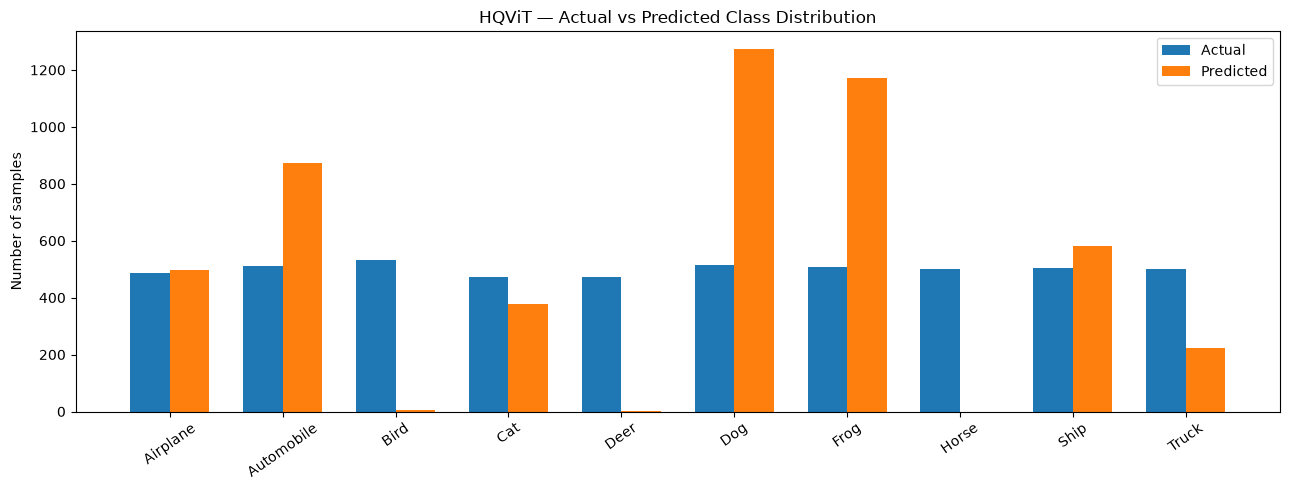

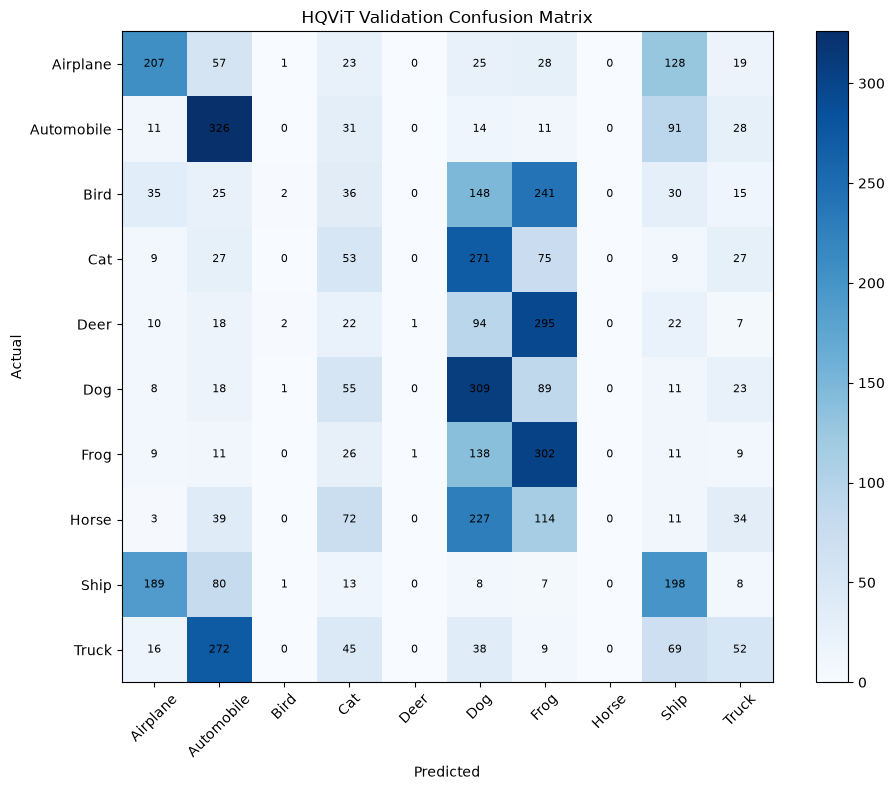


SECTION 98 COMPLETED
Validation samples: 5000
Diagnostics saved in: results/final_hqvit


In [24]:
# ============================================================
# SECTION 98 — HQViT CLASS COLLAPSE DIAGNOSTICS
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix

# 1. Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# 2. Load trained checkpoint
checkpoint_path = "models_clean/final_hqvit/rebuilt_hqvit_final.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Create model instance
model = HQViT().to(device)

# Load trained weights
model.load_state_dict(checkpoint["model_state_dict"])

# Evaluation mode
model.eval()

print("Rebuilt HQViT checkpoint loaded successfully.")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

# 3. Recreate validation loader
diagnostic_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# 4. Generate predictions
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in diagnostic_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

# 5. Actual vs predicted distribution
actual_counts = np.bincount(y_true, minlength=10)
predicted_counts = np.bincount(y_pred, minlength=10)

comparison = pd.DataFrame({
    "Class": class_names,
    "Actual_Count": actual_counts,
    "Predicted_Count": predicted_counts,
    "Prediction_Ratio": predicted_counts / np.maximum(actual_counts, 1)
})

print("\nACTUAL VS PREDICTED DISTRIBUTION")
display(comparison)

# 6. Prediction entropy
probabilities = predicted_counts / predicted_counts.sum()

entropy = -np.sum(
    probabilities * np.log(probabilities + 1e-12)
)

normalized_entropy = entropy / np.log(10)

print("\nPREDICTION COLLAPSE SUMMARY")
print("Prediction entropy:", round(entropy, 4))
print("Normalized entropy:", round(normalized_entropy, 4))
print("Classes never predicted:", [
    class_names[i]
    for i in range(10)
    if predicted_counts[i] == 0
])

# 7. Classification report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

# 8. Distribution chart
x = np.arange(10)
width = 0.35

plt.figure(figsize=(13, 5))
plt.bar(x - width/2, actual_counts, width, label="Actual")
plt.bar(x + width/2, predicted_counts, width, label="Predicted")

plt.xticks(x, class_names, rotation=35)
plt.ylabel("Number of samples")
plt.title("HQViT — Actual vs Predicted Class Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("HQViT Validation Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

# 10. Save diagnostics
output_dir = "results/final_hqvit"
os.makedirs(output_dir, exist_ok=True)

comparison.to_csv(
    os.path.join(output_dir, "class_collapse_diagnostics.csv"),
    index=False
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(os.path.join(output_dir, "confusion_matrix_verified.csv"))

print("\nSECTION 98 COMPLETED")
print("Validation samples:", len(y_true))
print("Diagnostics saved in:", output_dir)

In [25]:
# ============================================================
# SECTION 99 — HQViT REPRESENTATION AND GRADIENT AUDIT
# ============================================================

import torch
import numpy as np
import pandas as pd

model.eval()

# Locate important layers
print("MODEL ARCHITECTURE")
print(model)

print("\nTRAINABLE PARAMETER GROUPS")

for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        print(
            f"{name:65s} "
            f"Shape={str(tuple(parameter.shape)):20s} "
            f"Parameters={parameter.numel():,}"
        )

# Gradient availability and magnitude
print("\nGRADIENT AUDIT")

for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        if parameter.grad is None:
            print(f"{name}: No gradient currently stored")
        else:
            print(
                f"{name}: "
                f"Gradient norm={parameter.grad.norm().item():.8f}"
            )

# Checkpoint integrity
print("\nCHECKPOINT INFORMATION")
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Device:", next(model.parameters()).device)
print("Training mode:", model.training)

# Check output distribution on a validation batch
images, labels = next(iter(diagnostic_loader))
images = images.to(device)

with torch.no_grad():
    logits = model(images)
    probabilities = torch.softmax(logits, dim=1)

print("\nOUTPUT DIAGNOSTICS")
print("Logit shape:", tuple(logits.shape))
print("Logit mean:", logits.mean().item())
print("Logit std:", logits.std().item())
print("Probability mean:", probabilities.mean().item())
print("Probability std:", probabilities.std().item())
print("Finite logits:", torch.isfinite(logits).all().item())

print("\nSECTION 99 COMPLETED")

MODEL ARCHITECTURE
HQViT(
  (vit): ViTBackbone(
    (patch_embed): Conv2d(3, 128, kernel_size=(4, 4), stride=(4, 4))
    (dropout): Dropout(p=0.1, inplace=False)
    (transformer): TransformerEncoder(
      (layers): ModuleList(
        (0-3): 4 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
    )
  )
  (projection_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=Tr

In [26]:
# ============================================================
# SECTION 100 — HQViT REPRESENTATION AUDIT
# ============================================================

import torch
import numpy as np
import pandas as pd

model.eval()

activations = {}

def capture_projection_norm(module, inputs, output):
    activations["normalized_features"] = output.detach()

def capture_projection(module, inputs, output):
    activations["projected_features"] = output.detach()

def capture_classifier(module, inputs, output):
    activations["classifier_output"] = output.detach()

# Register hooks
handles = [
    model.projection_norm.register_forward_hook(capture_projection_norm),
    model.projection.register_forward_hook(capture_projection),
    model.classifier.register_forward_hook(capture_classifier)
]

# Get one validation batch
images, labels = next(iter(diagnostic_loader))
images = images.to(device)

# Forward pass
with torch.no_grad():
    logits = model(images)

# Remove hooks
for handle in handles:
    handle.remove()

# Analyse representations
print("========== REPRESENTATION AUDIT ==========")

for name, tensor in activations.items():
    print(f"\n{name}")
    print("Shape:", tuple(tensor.shape))
    print("Mean:", tensor.mean().item())
    print("Std:", tensor.std().item())
    print("Minimum:", tensor.min().item())
    print("Maximum:", tensor.max().item())
    print("Finite:", torch.isfinite(tensor).all().item())

# Projection dimensionality analysis
features = activations["projected_features"]

print("\n========== PROJECTION ANALYSIS ==========")
print("Projection shape:", tuple(features.shape))
print("Per-dimension standard deviation:")

for i in range(features.shape[-1]):
    print(
        f"Dimension {i}: "
        f"{features[:, i].std().item():.6f}"
    )

# Classifier output analysis
print("\n========== CLASSIFIER ANALYSIS ==========")
print("Logit shape:", tuple(logits.shape))
print("Logit standard deviation:", logits.std().item())

print("\nSECTION 100 COMPLETED")

========== REPRESENTATION AUDIT ==========

normalized_features
Shape: (32, 128)
Mean: 2.3208558559417725e-06
Std: 0.9982602000236511
Minimum: -3.887667655944824
Maximum: 3.527451992034912
Finite: True

projected_features
Shape: (32, 4)
Mean: 0.0669635459780693
Std: 2.0234415531158447
Minimum: -3.6286816596984863
Maximum: 3.431288957595825
Finite: True

classifier_output
Shape: (32, 10)
Mean: -0.24529680609703064
Std: 1.0105547904968262
Minimum: -1.8397645950317383
Maximum: 1.4063386917114258
Finite: True

========== PROJECTION ANALYSIS ==========
Projection shape: (32, 4)
Per-dimension standard deviation:
Dimension 0: 1.041977
Dimension 1: 1.462250
Dimension 2: 2.095882
Dimension 3: 0.126434

========== CLASSIFIER ANALYSIS ==========
Logit shape: (32, 10)
Logit standard deviation: 1.0105547904968262

SECTION 100 COMPLETED


In [27]:
# ============================================================
# SECTION 101 — QUANTUM CIRCUIT GRADIENT AUDIT
# ============================================================

import torch
import numpy as np
import pandas as pd

model.zero_grad(set_to_none=True)
model.train()

images, labels = next(iter(diagnostic_loader))

images = images.to(device)
labels = labels.to(device)

# Forward and backward pass
outputs = model(images)
loss = torch.nn.functional.cross_entropy(outputs, labels)

loss.backward()

print("========== GRADIENT AUDIT ==========")
print("Loss:", loss.item())

gradient_results = []

for name, parameter in model.named_parameters():

    if parameter.requires_grad:

        if parameter.grad is None:
            grad_norm = None
            status = "NO GRADIENT"
        else:
            grad_norm = parameter.grad.norm().item()
            status = "ZERO" if grad_norm == 0 else "ACTIVE"

        gradient_results.append({
            "Parameter": name,
            "Shape": str(tuple(parameter.shape)),
            "Gradient Norm": grad_norm,
            "Status": status
        })

gradient_df = pd.DataFrame(gradient_results)

display(gradient_df)

# Projection gradient summary
print("\nPROJECTION GRADIENTS")

for name, parameter in model.named_parameters():
    if "projection" in name:
        print(
            name,
            "Gradient:",
            None if parameter.grad is None
            else parameter.grad.norm().item()
        )

# Quantum parameter summary
print("\nQUANTUM PARAMETER GRADIENTS")

for name, parameter in model.named_parameters():
    if "quantum" in name.lower():
        print(
            name,
            "Shape:", tuple(parameter.shape),
            "Gradient:",
            None if parameter.grad is None
            else parameter.grad.norm().item()
        )

# Restore evaluation mode
model.zero_grad(set_to_none=True)
model.eval()

# Save results
gradient_df.to_csv(
    "results/final_hqvit/gradient_audit.csv",
    index=False
)

print("\nSECTION 101 COMPLETED")

========== GRADIENT AUDIT ==========
Loss: 1.8952022790908813


,Parameter,Shape,Gradient Norm,Status
0,quantum_weights,"(2, 4, 2)",0.080693,ACTIVE
1,vit.cls_token,"(1, 1, 128)",0.212690,ACTIVE
2,vit.pos_embed,"(1, 65, 128)",0.275231,ACTIVE
3,vit.patch_embed.weight,"(128, 3, 4, 4)",1.843148,ACTIVE
4,vit.patch_embed.bias,"(128,)",0.557612,ACTIVE
...,...,...,...,...
56,projection.bias,"(4,)",0.077001,ACTIVE
57,classifier.0.weight,"(32, 4)",0.120657,ACTIVE
58,classifier.0.bias,"(32,)",0.068816,ACTIVE
59,classifier.2.weight,"(10, 32)",0.366025,ACTIVE



PROJECTION GRADIENTS
projection_norm.weight Gradient: 0.05499555170536041
projection_norm.bias Gradient: 0.04429538547992706
projection.weight Gradient: 1.0726312398910522
projection.bias Gradient: 0.07700144499540329

QUANTUM PARAMETER GRADIENTS
quantum_weights Shape: (2, 4, 2) Gradient: 0.08069256693124771

SECTION 101 COMPLETED


In [28]:
# ============================================================
# SECTION 102 — QUANTUM CIRCUIT SENSITIVITY AUDIT
# ============================================================

import torch
import numpy as np
import pandas as pd

model.eval()

print("========== QUANTUM IMPLEMENTATION ==========")

print("Quantum weights:")
print(model.quantum_weights.detach().cpu())

print("\nQuantum weights shape:")
print(tuple(model.quantum_weights.shape))

print("\nQuantum-related model attributes:")
for name in dir(model):
    if any(k in name.lower() for k in ["quantum", "circuit", "qnode", "device"]):
        try:
            value = getattr(model, name)
            print(name, ":", value)
        except Exception:
            pass

print("\n========== CIRCUIT SOURCE ==========")

import inspect

for name, obj in globals().copy().items():
    if callable(obj) and (
        "circuit" in name.lower()
        or "quantum" in name.lower()
    ):
        try:
            print(f"\n--- {name} ---")
            print(inspect.getsource(obj)[:6000])
        except Exception:
            pass

print("\n========== QUANTUM INPUT/OUTPUT TEST ==========")

# Capture quantum circuit output by hooking the classifier input.
# This is the representation immediately before the classifier.
captured = {}

def capture_classifier_input(module, inputs, output):
    captured["quantum_features"] = inputs[0].detach().clone()

handle = model.classifier.register_forward_hook(
    capture_classifier_input
)

images, labels = next(iter(diagnostic_loader))
images = images.to(device)

with torch.no_grad():
    _ = model(images)

handle.remove()

q_features = captured["quantum_features"]

print("Quantum representation shape:", tuple(q_features.shape))
print("Mean:", q_features.mean().item())
print("Std:", q_features.std().item())
print("Minimum:", q_features.min().item())
print("Maximum:", q_features.max().item())

print("\nPer-dimension standard deviation:")

for i in range(q_features.shape[-1]):
    print(
        f"Dimension {i}: "
        f"{q_features[:, i].std().item():.6f}"
    )

print("\nSECTION 102 COMPLETED")

========== QUANTUM IMPLEMENTATION ==========
Quantum weights:
tensor([[[ 4.6291e-03,  2.1769e-04],
         [-1.1512e-02,  5.2566e-05],
         [-1.7808e-03,  1.6006e-04],
         [-1.2008e-02,  1.5754e-02]],

        [[ 3.0044e-03, -4.0303e-03],
         [ 1.7664e-02,  8.1998e-03],
         [ 4.6234e-04,  5.5169e-03],
         [-5.1019e-03, -1.7279e-02]]])

Quantum weights shape:
(2, 4, 2)

Quantum-related model attributes:
quantum_weights : Parameter containing:
tensor([[[ 4.6291e-03,  2.1769e-04],
         [-1.1512e-02,  5.2566e-05],
         [-1.7808e-03,  1.6006e-04],
         [-1.2008e-02,  1.5754e-02]],

        [[ 3.0044e-03, -4.0303e-03],
         [ 1.7664e-02,  8.1998e-03],
         [ 4.6234e-04,  5.5169e-03],
         [-5.1019e-03, -1.7279e-02]]], requires_grad=True)

========== CIRCUIT SOURCE ==========

--- quantum_circuit ---
@qml.qnode(qdev, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):
    for w in range(N_QUBITS): qml.RY(inputs[w], 

CLASS-WISE QUANTUM REPRESENTATION STATISTICS


,Class,Samples,Feature_Mean,Feature_Std,Q0_Std,Q1_Std,Q2_Std,Q3_Std
0,0,488,-0.617922,0.629752,0.435248,0.646117,0.661524,0.642441
1,1,512,-0.418357,0.776278,0.293096,0.552958,0.508526,0.547798
2,2,532,0.201939,0.821577,0.840558,0.675774,0.590843,0.671384
3,3,471,0.198193,0.797549,0.617358,0.536989,0.597872,0.532538
4,4,471,0.314066,0.808565,0.800034,0.557752,0.537980,0.554242
5,5,514,0.217649,0.804289,0.642187,0.484218,0.597951,0.480973
6,6,507,0.363855,0.785728,0.785820,0.449346,0.555492,0.445323
7,7,500,0.230627,0.783681,0.717881,0.593220,0.640710,0.587651
8,8,504,-0.719518,0.527411,0.259553,0.422716,0.635875,0.421194
9,9,501,-0.338237,0.796642,0.274727,0.675646,0.510787,0.671932


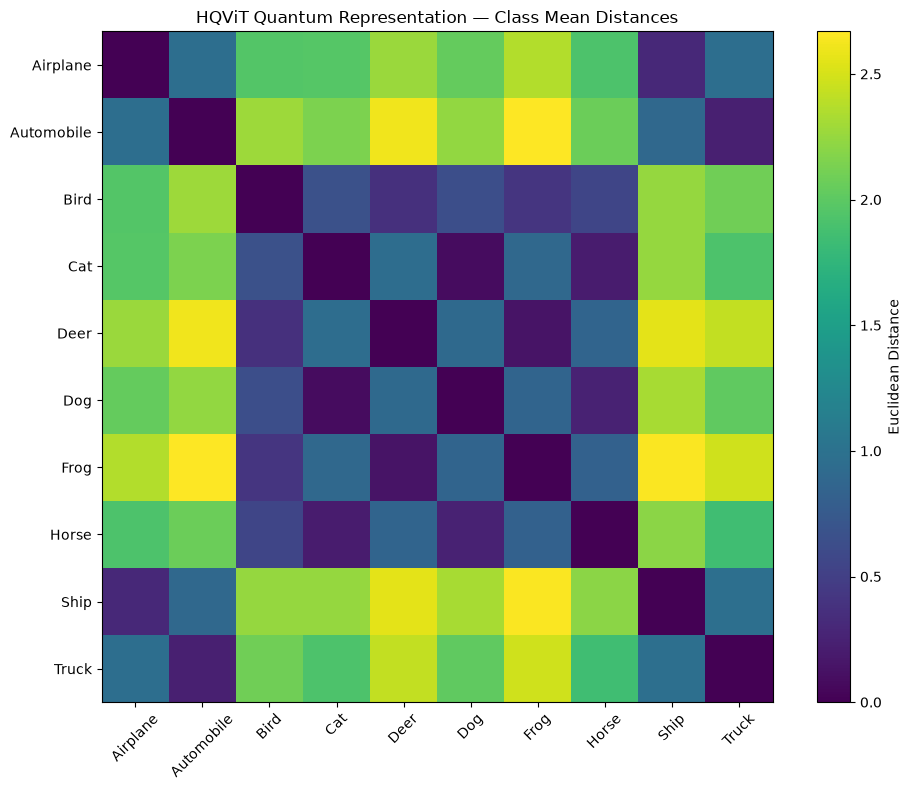

SECTION 103 COMPLETED


In [29]:
# ============================================================
# SECTION 103 — QUANTUM CLASS-WISE REPRESENTATION ANALYSIS
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model.eval()

captured = {}

def capture_quantum_features(module, inputs, output):
    captured["features"] = inputs[0].detach().cpu()

handle = model.classifier.register_forward_hook(
    capture_quantum_features
)

class_features = {i: [] for i in range(10)}

# Collect quantum representations by class
with torch.no_grad():
    for images, labels in diagnostic_loader:

        images = images.to(device)

        _ = model(images)

        features = captured["features"]

        for i, label in enumerate(labels):
            class_features[int(label)].append(features[i].numpy())

handle.remove()

# Calculate class-wise statistics
results = []

class_means = []

for class_id in range(10):

    features = np.asarray(class_features[class_id])

    mean_vector = features.mean(axis=0)
    class_means.append(mean_vector)

    results.append({
        "Class": class_id,
        "Samples": len(features),
        "Feature_Mean": features.mean(),
        "Feature_Std": features.std(),
        "Q0_Std": features[:, 0].std(),
        "Q1_Std": features[:, 1].std(),
        "Q2_Std": features[:, 2].std(),
        "Q3_Std": features[:, 3].std()
    })

results_df = pd.DataFrame(results)

print("CLASS-WISE QUANTUM REPRESENTATION STATISTICS")
display(results_df)

# Compare class mean representations
class_means = np.asarray(class_means)

distance_matrix = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        distance_matrix[i, j] = np.linalg.norm(
            class_means[i] - class_means[j]
        )

# Visualize class separation
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.figure(figsize=(10, 8))
plt.imshow(distance_matrix, cmap="viridis")
plt.colorbar(label="Euclidean Distance")
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.title("HQViT Quantum Representation — Class Mean Distances")
plt.tight_layout()
plt.show()

# Save results
results_df.to_csv(
    "results/final_hqvit/quantum_class_statistics.csv",
    index=False
)

pd.DataFrame(
    distance_matrix,
    index=class_names,
    columns=class_names
).to_csv(
    "results/final_hqvit/quantum_class_distance_matrix.csv"
)

print("SECTION 103 COMPLETED")

========== SEPARABILITY RESULTS ==========
Within-class scatter: 6748.124
Between-class scatter: 6553.53
Fisher discriminant ratio: 0.9711632


,Class,Samples,Within_Class_Variance,Mean_Vector_Norm
0,Airplane,488,0.364313,1.287018
1,Automobile,512,0.237587,1.469752
2,Bird,532,0.490765,0.948689
3,Cat,471,0.327634,1.179375
4,Deer,471,0.386937,1.209096
5,Dog,514,0.308938,1.241474
6,Frog,507,0.331577,1.293338
7,Horse,500,0.405777,1.022873
8,Ship,504,0.206949,1.534821
9,Truck,501,0.311092,1.323558



CLOSEST CLASS PAIRS


,Class_1,Class_2,Mean_Distance
25,Cat,Dog,0.092837
31,Deer,Frog,0.145843
27,Cat,Horse,0.208172
16,Automobile,Truck,0.232004
36,Dog,Horse,0.258636
7,Airplane,Ship,0.306814
18,Bird,Deer,0.372313
20,Bird,Frog,0.415809
21,Bird,Horse,0.558391
19,Bird,Dog,0.643477


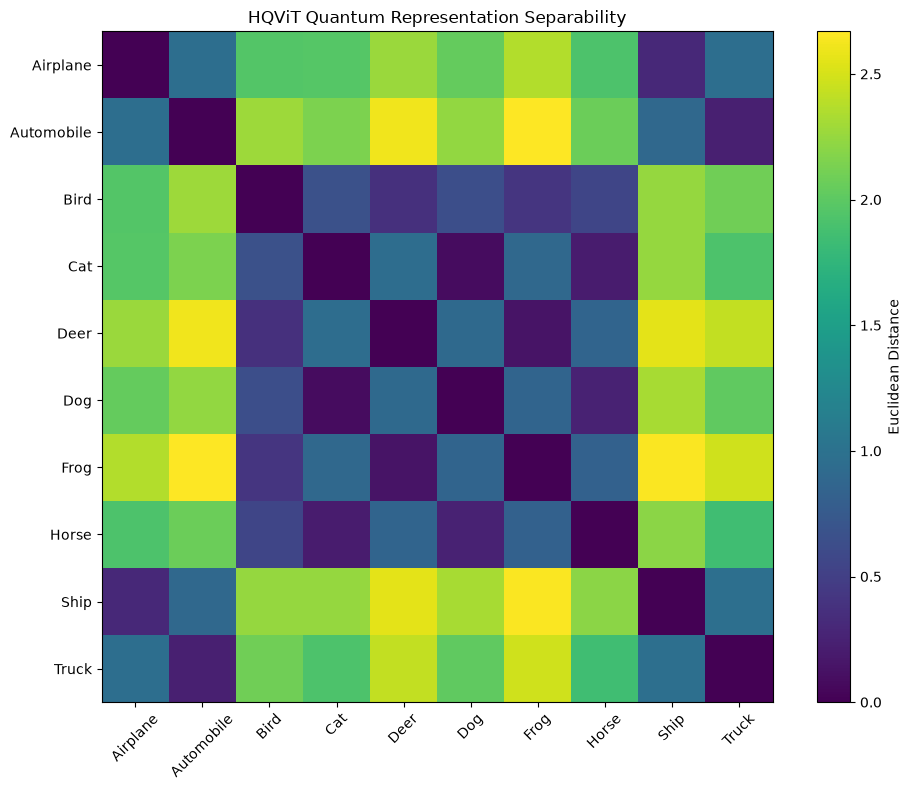


SECTION 104 COMPLETED


In [30]:
# ============================================================
# SECTION 104 — QUANTUM REPRESENTATION SEPARABILITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Recover features collected in Section 103
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

all_features = []
all_targets = []

for class_id in range(10):
    features = np.asarray(class_features[class_id])
    all_features.append(features)
    all_targets.extend([class_id] * len(features))

X = np.vstack(all_features)
y = np.asarray(all_targets)

# Global mean
global_mean = X.mean(axis=0)

within_scatter = 0.0
between_scatter = 0.0

class_stats = []

for class_id in range(10):

    Xc = X[y == class_id]
    class_mean = Xc.mean(axis=0)

    # Within-class scatter
    within_scatter += np.sum((Xc - class_mean) ** 2)

    # Between-class scatter
    between_scatter += len(Xc) * np.sum(
        (class_mean - global_mean) ** 2
    )

    class_stats.append({
        "Class": class_names[class_id],
        "Samples": len(Xc),
        "Within_Class_Variance": np.mean(
            np.var(Xc, axis=0)
        ),
        "Mean_Vector_Norm": np.linalg.norm(class_mean)
    })

# Fisher ratio
fisher_ratio = between_scatter / (within_scatter + 1e-12)

print("========== SEPARABILITY RESULTS ==========")
print("Within-class scatter:", within_scatter)
print("Between-class scatter:", between_scatter)
print("Fisher discriminant ratio:", fisher_ratio)

display(pd.DataFrame(class_stats))

# Pairwise class mean distances
means = np.array([
    X[y == i].mean(axis=0)
    for i in range(10)
])

distance_matrix = np.zeros((10, 10))

for i in range(10):
    for j in range(10):
        distance_matrix[i, j] = np.linalg.norm(
            means[i] - means[j]
        )

# Identify closest class pairs
pairs = []

for i in range(10):
    for j in range(i + 1, 10):
        pairs.append({
            "Class_1": class_names[i],
            "Class_2": class_names[j],
            "Mean_Distance": distance_matrix[i, j]
        })

pairs_df = pd.DataFrame(pairs).sort_values(
    "Mean_Distance"
)

print("\nCLOSEST CLASS PAIRS")
display(pairs_df.head(10))

# Plot separability matrix
plt.figure(figsize=(10, 8))
plt.imshow(distance_matrix, cmap="viridis")
plt.colorbar(label="Euclidean Distance")
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.title("HQViT Quantum Representation Separability")
plt.tight_layout()
plt.show()

# Save
output_dir = "results/final_hqvit"
os.makedirs(output_dir, exist_ok=True)

pd.DataFrame(class_stats).to_csv(
    f"{output_dir}/class_separability.csv",
    index=False
)

pairs_df.to_csv(
    f"{output_dir}/pairwise_separability.csv",
    index=False
)

print("\nSECTION 104 COMPLETED")

In [31]:
# ============================================================
# SECTION 105 — BASELINE CHECKPOINT INVENTORY
# ============================================================

import os
import torch

checkpoint_paths = {
    "Classical ViT": [
        "models_clean/section94/classical_vit_best.pt",
        "models_clean/section93/classical_vit_initial.pt"
    ],
    "Classical Bottleneck": [
        "models_clean/section94/classical_bottleneck_best.pt",
        "models_clean/section93/classical_bottleneck_initial.pt"
    ],
    "HQViT": [
        "models_clean/final_hqvit/rebuilt_hqvit_final.pt",
        "models_clean/section93/hqvit_initial.pt"
    ]
}

print("========== CHECKPOINT INVENTORY ==========")

for model_name, paths in checkpoint_paths.items():

    print(f"\n{model_name}")

    for path in paths:

        if os.path.exists(path):

            size_mb = os.path.getsize(path) / (1024 ** 2)

            print(f"  FOUND: {path}")
            print(f"  Size: {size_mb:.2f} MB")

            checkpoint = torch.load(
                path,
                map_location="cpu",
                weights_only=False
            )

            if isinstance(checkpoint, dict):
                print("  Keys:", list(checkpoint.keys()))

        else:
            print(f"  MISSING: {path}")

print("\nSECTION 105 COMPLETED")

========== CHECKPOINT INVENTORY ==========

Classical ViT
  MISSING: models_clean/section94/classical_vit_best.pt
  MISSING: models_clean/section93/classical_vit_initial.pt

Classical Bottleneck
  MISSING: models_clean/section94/classical_bottleneck_best.pt
  MISSING: models_clean/section93/classical_bottleneck_initial.pt

HQViT
  FOUND: models_clean/final_hqvit/rebuilt_hqvit_final.pt
  Size: 3.11 MB
  Keys: ['model_state_dict', 'model_class', 'model_parameters', 'epochs_completed', 'final_train_accuracy', 'final_validation_accuracy', 'saved_at']
  MISSING: models_clean/section93/hqvit_initial.pt

SECTION 105 COMPLETED


In [32]:
# ============================================================
# SECTION 106 — DATASET AND ENVIRONMENT RECOVERY AUDIT
# ============================================================

import torch
import os

print("========== DATASET AUDIT ==========")

required_variables = [
    "train_pool",
    "validation_dataset",
    "test_dataset",
    "train_full"
]

for name in required_variables:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE | Length: {len(obj)}")
    else:
        print(f"{name}: MISSING")

print("\n========== MODEL AUDIT ==========")

for name in ["HQViT", "ClassicalBottleneck"]:
    if name in globals():
        print(name, "AVAILABLE")
    else:
        print(name, "MISSING")

print("\n========== DEVICE ==========")
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
))

print("\n========== CHECKPOINT ==========")

path = "models_clean/final_hqvit/rebuilt_hqvit_final.pt"

print("HQViT checkpoint exists:", os.path.exists(path))

print("\nSECTION 106 COMPLETED")

========== DATASET AUDIT ==========
train_pool: AVAILABLE | Length: 45000
validation_dataset: AVAILABLE | Length: 5000
test_dataset: AVAILABLE | Length: 10000
train_full: MISSING

========== MODEL AUDIT ==========
HQViT AVAILABLE
ClassicalBottleneck AVAILABLE

========== DEVICE ==========
CUDA available: False
Device: cpu

========== CHECKPOINT ==========
HQViT checkpoint exists: True

SECTION 106 COMPLETED


In [33]:
# SECTION 107 — MODEL CONSTRUCTOR INSPECTION

import inspect

print("========== HQViT CONSTRUCTOR ==========")
print(inspect.signature(HQViT.__init__))

print("\n========== CLASSICAL BOTTLENECK CONSTRUCTOR ==========")
print(inspect.signature(ClassicalBottleneck.__init__))

print("\n========== HQViT FORWARD ==========")
print(inspect.signature(HQViT.forward))

print("\n========== CLASSICAL BOTTLENECK FORWARD ==========")
print(inspect.signature(ClassicalBottleneck.forward))

print("\nSECTION 107 COMPLETED")

========== HQViT CONSTRUCTOR ==========
(self)

========== CLASSICAL BOTTLENECK CONSTRUCTOR ==========
(self)

========== HQViT FORWARD ==========
(self, x)

========== CLASSICAL BOTTLENECK FORWARD ==========
(self, x)

SECTION 107 COMPLETED


In [ ]:
# ================================================================
# SECTION 108-109: CORRECTED THREE-MODEL COMPARISON
# 10 EPOCHS | MATCHED INITIALIZATION | CPU/GPU SUPPORT
# ================================================================

import os
import copy
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# -------------------- CONFIGURATION --------------------

SEED = 109
EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs("models_clean/section109", exist_ok=True)
os.makedirs("results/section109", exist_ok=True)

print("=" * 65)
print("CORRECTED THREE-MODEL EXPERIMENT")
print("=" * 65)
print("Device:", device)
print("Epochs per model:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Training samples:", len(train_pool))
print("Validation samples:", len(validation_dataset))


# -------------------- FEATURE EXTRACTION --------------------

def extract_vit_features(output):
    """
    Extract the 128-dimensional CLS representation
    from the ViT backbone.
    """

    if isinstance(output, dict):
        output = output.get("last_hidden_state", output.get("features"))

    if isinstance(output, (tuple, list)):
        output = output[0]

    if output.ndim == 3:
        output = output[:, 0, :]

    if output.ndim != 2:
        raise ValueError(
            f"Unexpected ViT feature shape: {output.shape}"
        )

    return output


# -------------------- CLASSICAL ViT --------------------

class ClassicalViTBaseline(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        self.vit = backbone
        self.norm = nn.LayerNorm(128)
        self.head = nn.Linear(128, 10)

    def forward(self, x):

        features = self.vit(x)
        features = extract_vit_features(features)

        features = self.norm(features)
        logits = self.head(features)

        return logits


# -------------------- CLASSICAL BOTTLENECK --------------------

class ClassicalBottleneckBaseline(nn.Module):

    def __init__(self, backbone, projection_norm,
                 projection, classifier):

        super().__init__()

        self.vit = backbone
        self.projection_norm = projection_norm
        self.projection = projection
        self.classifier = classifier

    def forward(self, x):

        features = self.vit(x)
        features = extract_vit_features(features)

        features = self.projection_norm(features)
        features = self.projection(features)

        logits = self.classifier(features)

        return logits


# -------------------- CREATE MATCHED MODELS --------------------

print("\n[1/5] Initializing reference HQViT...")

# Fresh HQViT initialization
hqvit_model = HQViT().to(device)

# All three models receive identical initial ViT backbone weights
classical_vit_model = ClassicalViTBaseline(
    copy.deepcopy(hqvit_model.vit)
).to(device)

classical_bottleneck_model = ClassicalBottleneckBaseline(
    backbone=copy.deepcopy(hqvit_model.vit),
    projection_norm=copy.deepcopy(hqvit_model.projection_norm),
    projection=copy.deepcopy(hqvit_model.projection),
    classifier=copy.deepcopy(hqvit_model.classifier)
).to(device)

print("Models initialized.")

# Verify matching backbone parameters
for name, parameter in hqvit_model.vit.state_dict().items():

    assert torch.equal(
        parameter,
        classical_vit_model.vit.state_dict()[name]
    ), f"Classical ViT backbone mismatch: {name}"

    assert torch.equal(
        parameter,
        classical_bottleneck_model.vit.state_dict()[name]
    ), f"Classical Bottleneck backbone mismatch: {name}"

print("Verified: all three models have identical initial ViT backbones.")

# Verify matching bottleneck and HQViT heads
assert torch.equal(
    hqvit_model.projection.weight,
    classical_bottleneck_model.projection.weight
)

assert torch.equal(
    hqvit_model.projection.bias,
    classical_bottleneck_model.projection.bias
)

print("Verified: bottleneck and HQViT projections are identical.")


# -------------------- FORWARD PASS VALIDATION --------------------

print("\n[2/5] Validating model outputs...")

sample_images, sample_labels = next(iter(
    DataLoader(train_pool, batch_size=4, shuffle=False)
))

sample_images = sample_images.to(device)

hqvit_model.eval()
classical_vit_model.eval()
classical_bottleneck_model.eval()

with torch.no_grad():

    output_vit = classical_vit_model(sample_images)
    output_bottleneck = classical_bottleneck_model(sample_images)
    output_hqvit = hqvit_model(sample_images)

for name, output in [
    ("Classical ViT", output_vit),
    ("Classical Bottleneck", output_bottleneck),
    ("HQViT", output_hqvit)
]:

    assert output.shape == (4, 10), (
        f"{name} returned unexpected shape: {output.shape}"
    )

    assert torch.isfinite(output).all(), (
        f"{name} produced non-finite values."
    )

    print(f"{name}: {tuple(output.shape)} - PASS")


# -------------------- DATA LOADERS --------------------

print("\n[3/5] Creating data loaders...")

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_pool,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))


# -------------------- TRAINING FUNCTION --------------------

def train_one_epoch(model, optimizer, criterion, epoch, model_name):

    model.train()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        # Progress update during the epoch
        if (batch_idx + 1) % 200 == 0:
            print(
                f"    {model_name} | Epoch {epoch}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)}",
                flush=True
            )

    train_loss = total_loss / len(train_loader)
    train_accuracy = accuracy_score(all_labels, all_predictions)
    train_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    elapsed = time.time() - start_time

    return train_loss, train_accuracy, train_f1, elapsed


# -------------------- VALIDATION FUNCTION --------------------

def validate_model(model, criterion):

    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in validation_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    val_loss = total_loss / len(validation_loader)

    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return val_loss, val_accuracy, val_f1


# -------------------- TRAIN ALL THREE MODELS --------------------

print("\n[4/5] Starting 10-epoch training...")
print("=" * 65)

models = {
    "Classical_ViT": classical_vit_model,
    "Classical_Bottleneck": classical_bottleneck_model,
    "HQViT": hqvit_model
}

experiment_results = {}
best_checkpoints = {}

criterion = nn.CrossEntropyLoss()

for model_name, current_model in models.items():

    print("\n" + "=" * 65)
    print("TRAINING:", model_name)
    print("=" * 65, flush=True)

    optimizer = torch.optim.AdamW(
        current_model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = []

    best_val_accuracy = -1.0
    best_state = None

    for epoch in range(1, EPOCHS + 1):

        print(
            f"\n{model_name} | Starting epoch {epoch}/{EPOCHS}",
            flush=True
        )

        train_loss, train_acc, train_f1, epoch_time = train_one_epoch(
            current_model,
            optimizer,
            criterion,
            epoch,
            model_name
        )

        val_loss, val_acc, val_f1 = validate_model(
            current_model,
            criterion
        )

        row = {
            "Model": model_name,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Train_Accuracy": train_acc,
            "Train_Macro_F1": train_f1,
            "Validation_Loss": val_loss,
            "Validation_Accuracy": val_acc,
            "Validation_Macro_F1": val_f1,
            "Epoch_Time_Seconds": epoch_time
        }

        history.append(row)

        print(
            f"\nEpoch {epoch}/{EPOCHS} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Time: {epoch_time:.1f}s",
            flush=True
        )

        # Save best validation checkpoint
        if val_acc > best_val_accuracy:

            best_val_accuracy = val_acc

            best_state = copy.deepcopy(
                current_model.state_dict()
            )

            torch.save(
                {
                    "model_name": model_name,
                    "model_state_dict": best_state,
                    "epoch": epoch,
                    "validation_accuracy": val_acc,
                    "validation_macro_f1": val_f1,
                    "seed": SEED
                },
                f"models_clean/section109/{model_name}_best.pt"
            )

        # Save progress after every epoch
        pd.DataFrame(history).to_csv(
            f"results/section109/{model_name}_history.csv",
            index=False
        )

    # Restore best validation checkpoint
    current_model.load_state_dict(best_state)

    experiment_results[model_name] = history

    best_checkpoints[model_name] = {
        "best_validation_accuracy": best_val_accuracy,
        "checkpoint": (
            f"models_clean/section109/{model_name}_best.pt"
        )
    }

    print(
        f"\nCompleted {model_name}. "
        f"Best validation accuracy: {best_val_accuracy:.4f}",
        flush=True
    )


# -------------------- FINAL COMPARISON --------------------

print("\n[5/5] Creating final comparison...")

all_history = []

for model_name, history in experiment_results.items():
    all_history.extend(history)

history_df = pd.DataFrame(all_history)

history_df.to_csv(
    "results/section109/three_model_training_history.csv",
    index=False
)

summary_rows = []

for model_name, history in experiment_results.items():

    df = pd.DataFrame(history)

    best_row = df.loc[
        df["Validation_Accuracy"].idxmax()
    ]

    summary_rows.append({
        "Model": model_name,
        "Best_Epoch": int(best_row["Epoch"]),
        "Best_Validation_Accuracy": best_row["Validation_Accuracy"],
        "Best_Validation_Macro_F1": best_row["Validation_Macro_F1"],
        "Final_Train_Accuracy": df.iloc[-1]["Train_Accuracy"],
        "Final_Validation_Accuracy": df.iloc[-1]["Validation_Accuracy"]
    })

comparison_df = pd.DataFrame(summary_rows)

comparison_df.to_csv(
    "results/section109/three_model_comparison.csv",
    index=False
)

print("\n" + "=" * 65)
print("FINAL THREE-MODEL COMPARISON")
print("=" * 65)

display(comparison_df)

print("\nSaved files:")
print(" - results/section109/three_model_training_history.csv")
print(" - results/section109/three_model_comparison.csv")
print(" - Individual model history CSVs")
print(" - Best model checkpoints")

print("\n10-EPOCH EXPERIMENT COMPLETED.")

CORRECTED THREE-MODEL EXPERIMENT
Device: cpu
Epochs per model: 10
Batch size: 32
Training samples: 45000
Validation samples: 5000

[1/5] Initializing reference HQViT...
Models initialized.
Verified: all three models have identical initial ViT backbones.
Verified: bottleneck and HQViT projections are identical.

[2/5] Validating model outputs...
Classical ViT: (4, 10) - PASS
Classical Bottleneck: (4, 10) - PASS
HQViT: (4, 10) - PASS

[3/5] Creating data loaders...
Training batches: 1407
Validation batches: 157

[4/5] Starting 10-epoch training...

TRAINING: Classical_ViT

Classical_ViT | Starting epoch 1/10
    Classical_ViT | Epoch 1/10 | Batch 200/1407
    Classical_ViT | Epoch 1/10 | Batch 400/1407
    Classical_ViT | Epoch 1/10 | Batch 600/1407
    Classical_ViT | Epoch 1/10 | Batch 800/1407
    Classical_ViT | Epoch 1/10 | Batch 1000/1407
    Classical_ViT | Epoch 1/10 | Batch 1200/1407
    Classical_ViT | Epoch 1/10 | Batch 1400/1407

Epoch 1/10 | Train Acc: 0.3368 | Val Acc: 0.42

In [1]:
import os
import pandas as pd
import torch

for name in ["Classical_ViT", "Classical_Bottleneck", "HQViT"]:

    history = f"results/section109/{name}_history.csv"
    checkpoint = f"models_clean/section109/{name}_best.pt"

    print(f"\n{name}")

    if os.path.exists(history):
        df = pd.read_csv(history)
        print("Completed epochs:", len(df))
        print("Last epoch:", df["Epoch"].max())
        print("Best validation accuracy:",
              round(df["Validation_Accuracy"].max(), 4))
    else:
        print("History missing")

    if os.path.exists(checkpoint):
        ckpt = torch.load(
            checkpoint,
            map_location="cpu",
            weights_only=False
        )
        print("Checkpoint epoch:", ckpt["epoch"])
        print("Checkpoint validation accuracy:",
              ckpt["validation_accuracy"])
    else:
        print("Checkpoint missing")


Classical_ViT
Completed epochs: 10
Last epoch: 10
Best validation accuracy: 0.649
Checkpoint epoch: 9
Checkpoint validation accuracy: 0.649

Classical_Bottleneck
Completed epochs: 1
Last epoch: 1
Best validation accuracy: 0.3614
Checkpoint epoch: 1
Checkpoint validation accuracy: 0.3614

HQViT
History missing
Checkpoint missing


In [2]:
import os
import torch

paths = [
    "models_clean/section108/classical_vit_initial.pt",
    "models_clean/section108/classical_bottleneck_initial.pt",
    "models_clean/section108/hqvit_initial.pt",
    "models_clean/final_hqvit/rebuilt_hqvit_final.pt",
    "models_clean/section109/Classical_Bottleneck_best.pt",
    "models_clean/section109/Classical_ViT_best.pt"
]

print("CHECKPOINT INVENTORY")
print("=" * 60)

for path in paths:
    if os.path.exists(path):
        print("[FOUND]", path,
              f"({os.path.getsize(path) / (1024*1024):.2f} MB)")
    else:
        print("[MISSING]", path)

CHECKPOINT INVENTORY
[FOUND] models_clean/section108/classical_vit_initial.pt (3.11 MB)
[FOUND] models_clean/section108/classical_bottleneck_initial.pt (3.11 MB)
[FOUND] models_clean/section108/hqvit_initial.pt (3.11 MB)
[FOUND] models_clean/final_hqvit/rebuilt_hqvit_final.pt (3.11 MB)
[FOUND] models_clean/section109/Classical_Bottleneck_best.pt (3.11 MB)
[FOUND] models_clean/section109/Classical_ViT_best.pt (3.11 MB)


In [21]:
# ================================================================
# SECTION 110: RECOVERY TRAINING
# Classical Bottleneck: Resume from Epoch 1 -> Epoch 10
# HQViT: Train Epoch 1 -> Epoch 10
# Classical ViT: Already completed; DO NOT RETRAIN
# ================================================================

import os
import copy
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

SEED = 109
EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("models_clean/section110", exist_ok=True)
os.makedirs("results/section110", exist_ok=True)

assert "HQViT" in globals(), "Run the original HQViT class definition first."
assert "train_pool" in globals(), "Run the dataset preparation cells first."
assert "validation_dataset" in globals(), "Validation dataset is missing."

print("DEVICE:", device)
print("TRAINING SAMPLES:", len(train_pool))
print("VALIDATION SAMPLES:", len(validation_dataset))


# ------------------------------------------------
# 2. MODEL DEFINITIONS
# ------------------------------------------------

def extract_vit_features(output):

    if isinstance(output, dict):
        output = output.get(
            "last_hidden_state",
            output.get("features")
        )

    if isinstance(output, (tuple, list)):
        output = output[0]

    if output.ndim == 3:
        output = output[:, 0, :]

    if output.ndim != 2:
        raise ValueError(
            f"Unexpected ViT output shape: {output.shape}"
        )

    return output


class ClassicalBottleneckBaseline(nn.Module):

    def __init__(
        self,
        backbone,
        projection_norm,
        projection,
        classifier
    ):
        super().__init__()

        self.vit = backbone
        self.projection_norm = projection_norm
        self.projection = projection
        self.classifier = classifier

    def forward(self, x):

        features = self.vit(x)
        features = extract_vit_features(features)

        features = self.projection_norm(features)
        features = self.projection(features)

        return self.classifier(features)


# ------------------------------------------------
# 3. CHECKPOINT LOADING UTILITIES
# ------------------------------------------------

def get_state_dict(path):

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict):

        if "model_state_dict" in checkpoint:
            return checkpoint["model_state_dict"], checkpoint

        if "state_dict" in checkpoint:
            return checkpoint["state_dict"], checkpoint

    return checkpoint, {}


# Load matched initial HQViT initialization
initial_hqvit_path = (
    "models_clean/section108/hqvit_initial.pt"
)

initial_state, initial_metadata = get_state_dict(
    initial_hqvit_path
)

initial_hqvit = HQViT().to(device)

initial_hqvit.load_state_dict(
    initial_state,
    strict=True
)

print("\nMatched HQViT initialization loaded.")


# ------------------------------------------------
# 4. INITIALIZE CLASSICAL BOTTLENECK
# ------------------------------------------------

classical_bottleneck_model = ClassicalBottleneckBaseline(
    backbone=copy.deepcopy(initial_hqvit.vit),
    projection_norm=copy.deepcopy(
        initial_hqvit.projection_norm
    ),
    projection=copy.deepcopy(
        initial_hqvit.projection
    ),
    classifier=copy.deepcopy(
        initial_hqvit.classifier
    )
).to(device)

bottleneck_best_path = (
    "models_clean/section109/Classical_Bottleneck_best.pt"
)

bottleneck_state, bottleneck_metadata = get_state_dict(
    bottleneck_best_path
)

classical_bottleneck_model.load_state_dict(
    bottleneck_state,
    strict=True
)

print("Classical Bottleneck restored from best checkpoint.")


# ------------------------------------------------
# 5. INITIALIZE HQViT
# ------------------------------------------------

hqvit_model = HQViT().to(device)

hqvit_model.load_state_dict(
    initial_state,
    strict=True
)

print("HQViT restored from matched initial checkpoint.")


# ------------------------------------------------
# 6. DATA LOADERS
# ------------------------------------------------

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_pool,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

criterion = nn.CrossEntropyLoss()

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(validation_loader))


# ------------------------------------------------
# 7. TRAINING AND VALIDATION
# ------------------------------------------------

def run_training_epoch(model, optimizer, model_name, epoch):

    model.train()

    total_loss = 0.0
    predictions_all = []
    labels_all = []

    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        predictions_all.extend(
            predictions.detach().cpu().numpy()
        )

        labels_all.extend(
            labels.detach().cpu().numpy()
        )

        if (batch_idx + 1) % 200 == 0:

            print(
                f"{model_name} | Epoch {epoch}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)}",
                flush=True
            )

    train_loss = total_loss / len(train_loader)

    train_acc = accuracy_score(
        labels_all,
        predictions_all
    )

    train_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    elapsed = time.time() - start_time

    return train_loss, train_acc, train_f1, elapsed


def run_validation(model):

    model.eval()

    total_loss = 0.0
    predictions_all = []
    labels_all = []

    with torch.no_grad():

        for images, labels in validation_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            predictions_all.extend(
                predictions.cpu().numpy()
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

    val_loss = total_loss / len(validation_loader)

    val_acc = accuracy_score(
        labels_all,
        predictions_all
    )

    val_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    return val_loss, val_acc, val_f1


# ------------------------------------------------
# 8. RECOVERABLE TRAINING LOOP
# ------------------------------------------------

def train_with_recovery(
    model,
    model_name,
    starting_epoch,
    previous_best_accuracy
):

    history_path = (
        f"results/section110/{model_name}_history.csv"
    )

    latest_path = (
        f"models_clean/section110/{model_name}_latest.pt"
    )

    best_path = (
        f"models_clean/section110/{model_name}_best.pt"
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = []

    if os.path.exists(history_path):
        history = pd.read_csv(history_path).to_dict("records")

    start_epoch = starting_epoch
    best_accuracy = previous_best_accuracy

    # Restore latest recovery checkpoint if available
    if os.path.exists(latest_path):

        recovery_state, recovery_metadata = get_state_dict(
            latest_path
        )

        model.load_state_dict(
            recovery_state,
            strict=True
        )

        optimizer_state = recovery_metadata.get(
            "optimizer_state_dict"
        )

        if optimizer_state is not None:
            optimizer.load_state_dict(optimizer_state)

        start_epoch = max(
            start_epoch,
            recovery_metadata["epoch"] + 1
        )

        best_accuracy = max(
            best_accuracy,
            recovery_metadata.get(
                "best_validation_accuracy",
                0.0
            )
        )

        print(
            f"\nRecovered {model_name} from epoch "
            f"{recovery_metadata['epoch']}"
        )

    print("\n" + "=" * 65)
    print("TRAINING:", model_name)
    print("Starting epoch:", start_epoch)
    print("Target epoch:", EPOCHS)
    print("=" * 65, flush=True)

    for epoch in range(start_epoch, EPOCHS + 1):

        print(
            f"\n{model_name} | Starting epoch {epoch}/{EPOCHS}",
            flush=True
        )

        train_loss, train_acc, train_f1, elapsed = (
            run_training_epoch(
                model,
                optimizer,
                model_name,
                epoch
            )
        )

        val_loss, val_acc, val_f1 = run_validation(model)

        row = {
            "Model": model_name,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Train_Accuracy": train_acc,
            "Train_Macro_F1": train_f1,
            "Validation_Loss": val_loss,
            "Validation_Accuracy": val_acc,
            "Validation_Macro_F1": val_f1,
            "Epoch_Time_Seconds": elapsed
        }

        history.append(row)

        # Save history immediately after each epoch
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # Save complete recovery state
        recovery_checkpoint = {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "best_validation_accuracy": best_accuracy,
            "model_name": model_name
        }

        torch.save(
            recovery_checkpoint,
            latest_path
        )

        # Save best validation checkpoint
        if val_acc > best_accuracy:

            best_accuracy = val_acc

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "epoch": epoch,
                    "validation_accuracy": val_acc,
                    "validation_macro_f1": val_f1,
                    "model_name": model_name
                },
                best_path
            )

        # Update latest checkpoint with current best score
        recovery_checkpoint["best_validation_accuracy"] = (
            best_accuracy
        )

        torch.save(
            recovery_checkpoint,
            latest_path
        )

        print(
            f"\nEpoch {epoch}/{EPOCHS} COMPLETE\n"
            f"Train Accuracy: {train_acc:.4f}\n"
            f"Validation Accuracy: {val_acc:.4f}\n"
            f"Validation Macro F1: {val_f1:.4f}\n"
            f"Best Validation Accuracy: {best_accuracy:.4f}\n"
            f"Time: {elapsed:.1f} seconds",
            flush=True
        )

    print(
        f"\n{model_name} training finished. "
        f"Best validation accuracy: {best_accuracy:.4f}"
    )

    # Restore best model after training
    best_state, _ = get_state_dict(best_path)

    model.load_state_dict(
        best_state,
        strict=True
    )

    return model, pd.DataFrame(history)


# ------------------------------------------------
# 9. RESUME BOTTLENECK
# ------------------------------------------------

# Existing epoch 1 history and best checkpoint are preserved.
# We start at epoch 2.

print("\n\nSTARTING CLASSICAL BOTTLENECK RECOVERY")

bottleneck_model, bottleneck_history = train_with_recovery(
    model=classical_bottleneck_model,
    model_name="Classical_Bottleneck",
    starting_epoch=2,
    previous_best_accuracy=0.3614
)


# ------------------------------------------------
# 10. TRAIN HQViT
# ------------------------------------------------

print("\n\nSTARTING HQViT TRAINING")

hqvit_model, hqvit_history = train_with_recovery(
    model=hqvit_model,
    model_name="HQViT",
    starting_epoch=1,
    previous_best_accuracy=0.0
)


# ------------------------------------------------
# 11. FINAL COMPARISON
# ------------------------------------------------

print("\n" + "=" * 65)
print("RECOVERY TRAINING COMPLETED")
print("=" * 65)

comparison = []

# Classical ViT: existing completed experiment
vit_history = pd.read_csv(
    "results/section109/Classical_ViT_history.csv"
)

vit_best = vit_history.loc[
    vit_history["Validation_Accuracy"].idxmax()
]

comparison.append({
    "Model": "Classical ViT",
    "Completed_Epochs": len(vit_history),
    "Best_Epoch": int(vit_best["Epoch"]),
    "Best_Validation_Accuracy": vit_best["Validation_Accuracy"],
    "Best_Validation_Macro_F1": vit_best["Validation_Macro_F1"]
})

# Bottleneck
bottleneck_best = bottleneck_history.loc[
    bottleneck_history["Validation_Accuracy"].idxmax()
]

comparison.append({
    "Model": "Classical Bottleneck",
    "Completed_Epochs": len(bottleneck_history),
    "Best_Epoch": int(bottleneck_best["Epoch"]),
    "Best_Validation_Accuracy": bottleneck_best["Validation_Accuracy"],
    "Best_Validation_Macro_F1": bottleneck_best["Validation_Macro_F1"]
})

# HQViT
hqvit_best = hqvit_history.loc[
    hqvit_history["Validation_Accuracy"].idxmax()
]

comparison.append({
    "Model": "HQViT",
    "Completed_Epochs": len(hqvit_history),
    "Best_Epoch": int(hqvit_best["Epoch"]),
    "Best_Validation_Accuracy": hqvit_best["Validation_Accuracy"],
    "Best_Validation_Macro_F1": hqvit_best["Validation_Macro_F1"]
})

comparison_df = pd.DataFrame(comparison)

comparison_df.to_csv(
    "results/section110/three_model_comparison.csv",
    index=False
)

display(comparison_df)

print("\nAll recovery artifacts saved.")

DEVICE: cpu
TRAINING SAMPLES: 45000
VALIDATION SAMPLES: 5000

Matched HQViT initialization loaded.
Classical Bottleneck restored from best checkpoint.
HQViT restored from matched initial checkpoint.

Training batches: 1407
Validation batches: 157


STARTING CLASSICAL BOTTLENECK RECOVERY

TRAINING: Classical_Bottleneck
Starting epoch: 2
Target epoch: 10

Classical_Bottleneck | Starting epoch 2/10
Classical_Bottleneck | Epoch 2/10 | Batch 200/1407
Classical_Bottleneck | Epoch 2/10 | Batch 400/1407
Classical_Bottleneck | Epoch 2/10 | Batch 600/1407
Classical_Bottleneck | Epoch 2/10 | Batch 800/1407
Classical_Bottleneck | Epoch 2/10 | Batch 1000/1407
Classical_Bottleneck | Epoch 2/10 | Batch 1200/1407
Classical_Bottleneck | Epoch 2/10 | Batch 1400/1407

Epoch 2/10 COMPLETE
Train Accuracy: 0.3836
Validation Accuracy: 0.4206
Validation Macro F1: 0.4088
Best Validation Accuracy: 0.4206
Time: 381.0 seconds

Classical_Bottleneck | Starting epoch 3/10
Classical_Bottleneck | Epoch 3/10 | Batch 20

,Model,Completed_Epochs,Best_Epoch,Best_Validation_Accuracy,Best_Validation_Macro_F1
0,Classical ViT,10,9,0.6490,0.643896
1,Classical Bottleneck,9,10,0.6090,0.604220
2,HQViT,10,10,0.5628,0.544792



All recovery artifacts saved.
